# 1, Calculation

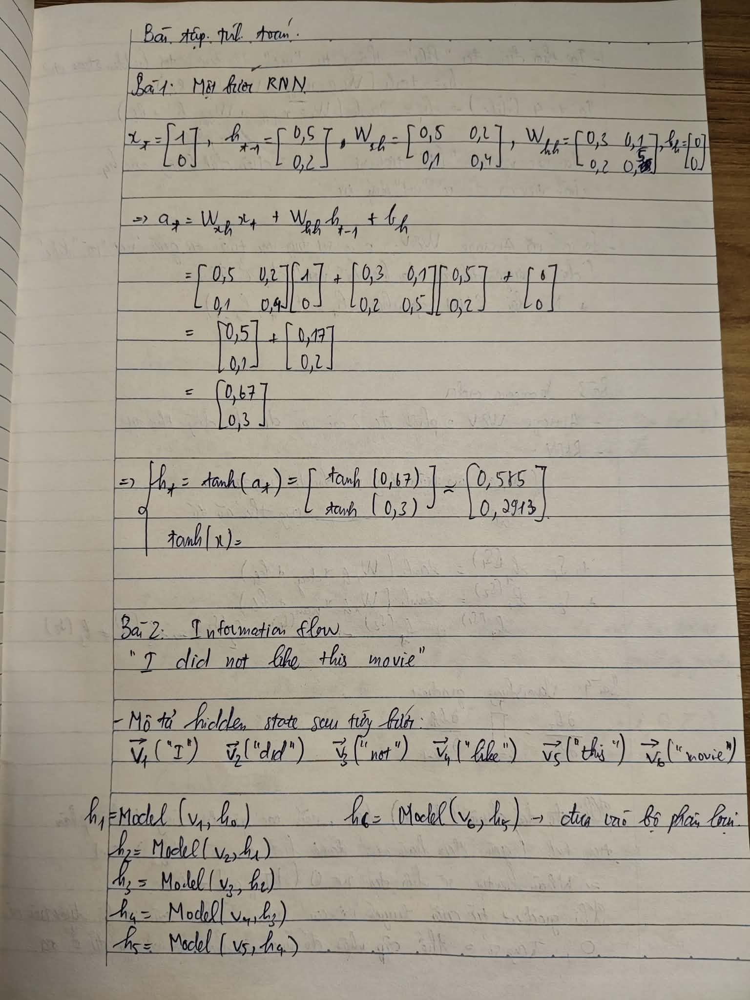

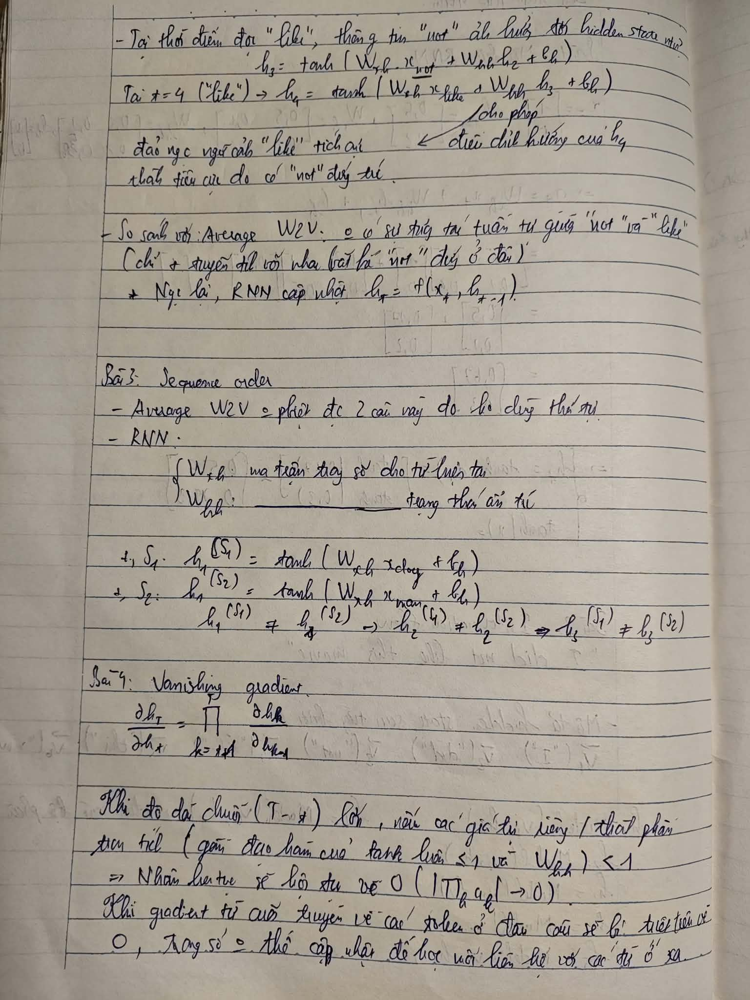

# 2, Prediction

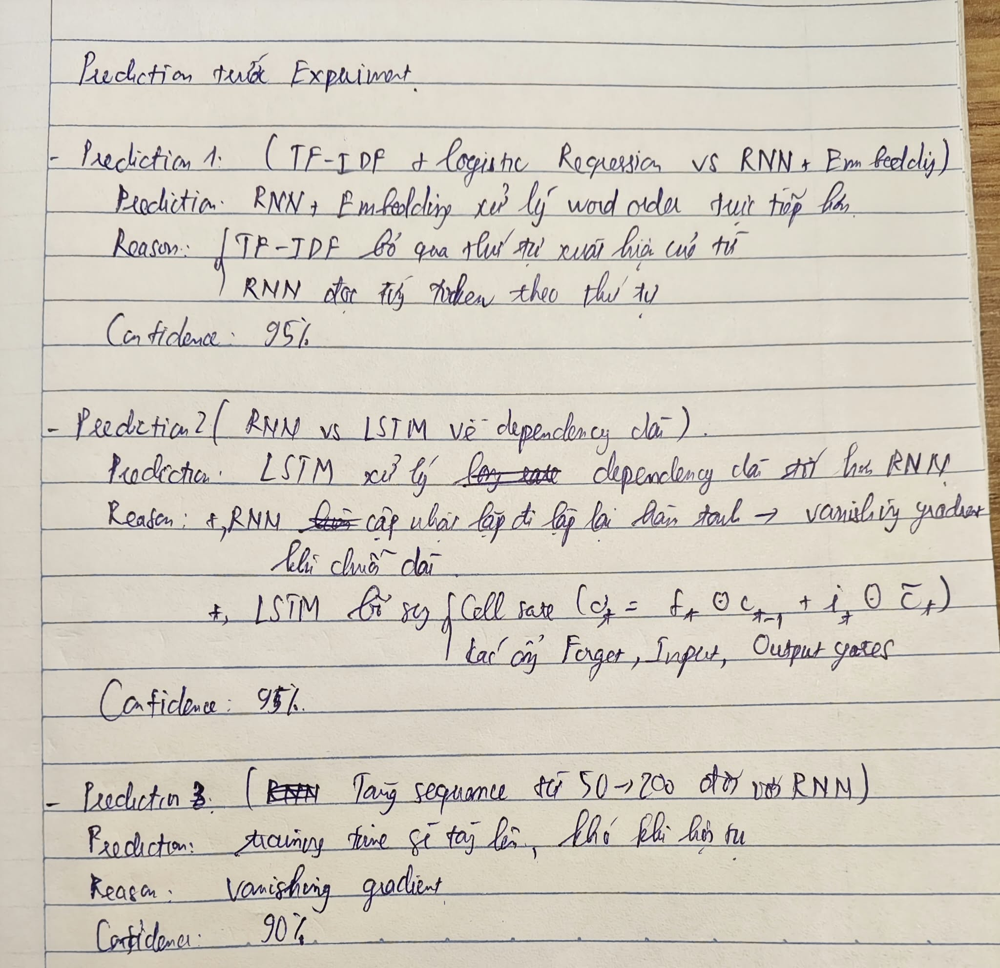

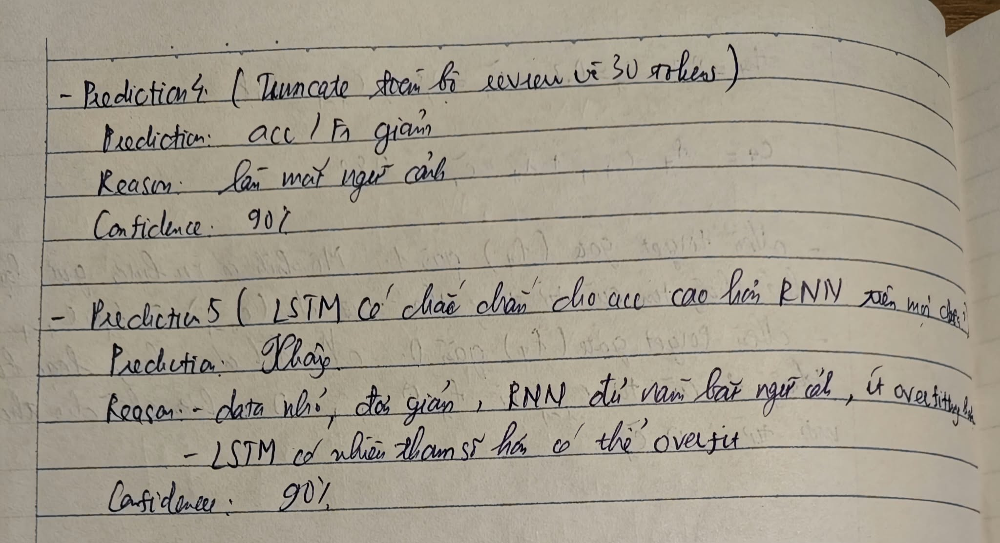

# 3, Dataset & sequence analysis

In [1]:
%cd /content/drive/MyDrive/Classroom/K68.NLP&DL.2026.09/Lab05

/content/drive/MyDrive/Classroom/K68.NLP&DL.2026.09/Lab05


In [2]:
import time
import re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

imdb = load_dataset("stanfordnlp/imdb", name="plain_text")
print(imdb)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


1. Tổng số samples: 50000 (Train: 25000, Test: 25000)
2. Số lượng classes: 2 (0 = negative, 1 = positive)
3. Phân phối nhãn (Class distribution):
{0: 25000, 1: 25000}
4. Minimum sequence length: 4 từ
5. Median sequence length:  173.0 từ
6. Mean sequence length:    231.2 từ
7. Maximum sequence length: 2470 từ
8. Phân vị 75% và 90%:      75% = 280, 90% = 451
9. Số văn bản trùng lặp (Duplicate documents): 418
10. Missing text (rỗng/null): 0
11. Missing labels: 0


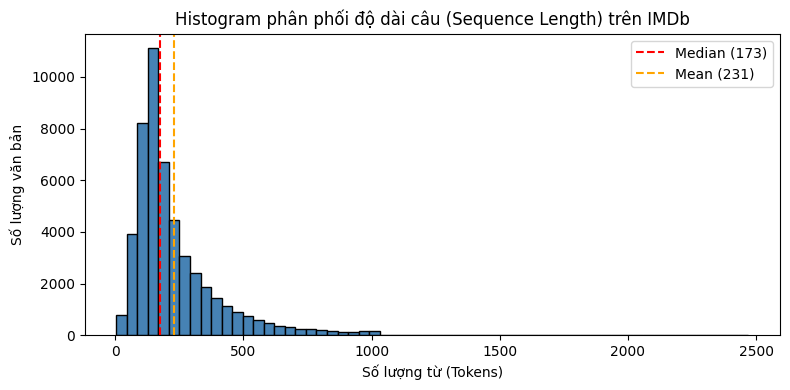

In [3]:
df_train = pd.DataFrame(imdb['train'])
df_test = pd.DataFrame(imdb['test'])
df_all = pd.concat([df_train, df_test], ignore_index=True)

# Tính độ dài câu (theo số từ tách bằng khoảng trắng)
df_all['seq_len'] = df_all['text'].apply(lambda x: len(str(x).split()))

print(f"1. Tổng số samples: {len(df_all)} (Train: {len(df_train)}, Test: {len(df_test)})")
print(f"2. Số lượng classes: {df_all['label'].nunique()} (0 = negative, 1 = positive)")
print(f"3. Phân phối nhãn (Class distribution):\n{df_all['label'].value_counts().to_dict()}")
print(f"4. Minimum sequence length: {df_all['seq_len'].min()} từ")
print(f"5. Median sequence length:  {df_all['seq_len'].median():.1f} từ")
print(f"6. Mean sequence length:    {df_all['seq_len'].mean():.1f} từ")
print(f"7. Maximum sequence length: {df_all['seq_len'].max()} từ")
print(f"8. Phân vị 75% và 90%:      75% = {np.percentile(df_all['seq_len'], 75):.0f}, 90% = {np.percentile(df_all['seq_len'], 90):.0f}")
print(f"9. Số văn bản trùng lặp (Duplicate documents): {df_all['text'].duplicated().sum()}")
print(f"10. Missing text (rỗng/null): {df_all['text'].isnull().sum() + (df_all['text'].str.strip() == '').sum()}")
print(f"11. Missing labels: {df_all['label'].isnull().sum()}")

# Vẽ Histogram Sequence Length
plt.figure(figsize=(8, 4))
plt.hist(df_all['seq_len'], bins=60, color='steelblue', edgecolor='black')
plt.axvline(df_all['seq_len'].median(), color='red', linestyle='--', label=f"Median ({df_all['seq_len'].median():.0f})")
plt.axvline(df_all['seq_len'].mean(), color='orange', linestyle='--', label=f"Mean ({df_all['seq_len'].mean():.0f})")
plt.title("Histogram phân phối độ dài câu (Sequence Length) trên IMDb")
plt.xlabel("Số lượng từ (Tokens)")
plt.ylabel("Số lượng văn bản")
plt.legend()
plt.tight_layout()
plt.show()

In [4]:
# Xóa các dòng trùng lặp để tránh trùng mẫu giữa các tập
df_train = df_train.drop_duplicates(subset=['text']).reset_index(drop=True)
df_test = df_test.drop_duplicates(subset=['text']).reset_index(drop=True)

# Loại bỏ những câu trong tập Test vô tình xuất hiện trong tập Train
df_test = df_test[~df_test['text'].isin(df_train['text'])].reset_index(drop=True)

Nếu phải chọn max_length, nên chọn dựa trên thông tin nào?

- Dựa trên phân phối thống kê độ dài chuỗi (median, mean và các mức phân vị percentile như 75%–90% trên histogram)

Phân biệt padding và truncation:

- Padding: Khi câu ngắn hơn max_length, chèn thêm các token đặc biệt 0 = \<PAD> vào để mọi câu trong cùng một batch có kích thước bằng nhau (phục vụ tính toán ma trận song song). Padding không mang thông tin ngôn ngữ thực sự.

- Truncation: Khi câu dài hơn max_length, cắt bỏ các token vượt quá giới hạn để cố định chiều dài chuỗi; việc này giúp giới hạn bộ nhớ và thời gian chạy nhưng có nguy cơ làm mất thông tin ngữ cảnh ở phần bị cắt.

# 4, RNN cell implementation

In [5]:
class SimpleRNNCell:
    def __init__(self, input_size, hidden_size):
        self.input_size = input_size
        self.hidden_size = hidden_size
        # Khởi tạo trọng số ngẫu nhiên nhỏ
        self.W_xh = np.random.randn(hidden_size, input_size) * 0.1
        self.W_hh = np.random.randn(hidden_size, hidden_size) * 0.1
        self.b_h = np.zeros((hidden_size, 1))

    def forward(self, x_t, h_prev):
        a_t = np.dot(self.W_xh, x_t) + np.dot(self.W_hh, h_prev) + self.b_h
        h_t = np.tanh(a_t)
        return h_t

# 1. Kiểm tra lại kết quả Bài tập 1 (Calculation)
cell_test = SimpleRNNCell(input_size=2, hidden_size=2)
cell_test.W_xh = np.array([[0.5, 0.2], [0.1, 0.4]])
cell_test.W_hh = np.array([[0.3, 0.1], [0.2, 0.5]])
cell_test.b_h  = np.array([[0.0], [0.0]])

x_t = np.array([[1.0], [0.0]])
h_prev = np.array([[0.5], [0.2]])
h_t_custom = cell_test.forward(x_t, h_prev)
print("Kết quả SimpleRNNCell (Bài 1):\n", h_t_custom)

# 2. Đối chiếu với torch.nn.RNNCell của PyTorch
torch_cell = nn.RNNCell(input_size=2, hidden_size=2, bias=True, nonlinearity='tanh')
with torch.no_grad():
    torch_cell.weight_ih.copy_(torch.tensor(cell_test.W_xh, dtype=torch.float32))
    torch_cell.weight_hh.copy_(torch.tensor(cell_test.W_hh, dtype=torch.float32))
    torch_cell.bias_ih.zero_()
    torch_cell.bias_hh.copy_(torch.tensor(cell_test.b_h.squeeze(), dtype=torch.float32))

x_t_tensor = torch.tensor([[1.0, 0.0]], dtype=torch.float32)
h_prev_tensor = torch.tensor([[0.5, 0.2]], dtype=torch.float32)
h_t_torch = torch_cell(x_t_tensor, h_prev_tensor).detach().numpy().T

print("Kết quả torch.nn.RNNCell:\n", h_t_torch)
print("Sai số tuyệt đối lớn nhất:", np.max(np.abs(h_t_custom - h_t_torch)))

Kết quả SimpleRNNCell (Bài 1):
 [[0.58497988]
 [0.29131261]]
Kết quả torch.nn.RNNCell:
 [[0.5849799 ]
 [0.29131263]]
Sai số tuyệt đối lớn nhất: 2.2493324813854798e-08


# 5, RNN/LSTM/GRU experiment & Baseline

In [6]:
# 10000 mẫu train/val và 5000 mẫu test
train_texts_full, val_texts, train_labels_full, val_labels = train_test_split(
    df_train['text'].tolist(), df_train['label'].tolist(),
    test_size=0.2, random_state=SEED, stratify=df_train['label']
)
train_texts = train_texts_full[:8000]
train_labels = train_labels_full[:8000]
val_texts = val_texts[:2000]
val_labels = val_labels[:2000]

test_texts, _, test_labels, _ = train_test_split(
    df_test['text'].tolist(), df_test['label'].tolist(),
     train_size=4000, random_state=SEED, stratify=df_test['label']
)

# Hàm tách từ cơ bản
def simple_tokenize(text):
    text = re.sub(r"<br\s*/?>", " ", text.lower())
    return re.findall(r"\b\w+\b", text)

# Xây dựng Vocabulary từ tập train
MAX_VOCAB = 10000
counter = Counter()
for text in train_texts:
    counter.update(simple_tokenize(text))

vocab = {"<PAD>": 0, "<UNK>": 1}
for word, _ in counter.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

print("Kích thước Vocabulary:", len(vocab))

# Hàm chuyển văn bản sang chuỗi ID có padding & truncation (post-padding, giữ token cuối ở vị trí cuối)
def encode_texts(texts, vocab, max_len):
    encoded = np.zeros((len(texts), max_len), dtype=np.int64)
    retained_tokens = 0
    total_tokens = 0
    for i, text in enumerate(texts):
        tokens = simple_tokenize(text)
        total_tokens += len(tokens)
        ids = [vocab.get(w, 1) for w in tokens[:max_len]]
        retained_tokens += len(ids)
        # Đặt token vào cuối chuỗi (left-padding) hoặc đầu chuỗi (right-padding)
        if len(ids) > 0:
            encoded[i, -len(ids):] = ids
    pct_retained = (retained_tokens / total_tokens) * 100 if total_tokens > 0 else 0
    return torch.tensor(encoded, dtype=torch.long), pct_retained

Kích thước Vocabulary: 10000


## Baseline TF-IDF + Logistic Regression

In [7]:
t0 = time.time()
tfidf = TfidfVectorizer(max_features=MAX_VOCAB, stop_words=None)
X_train_tfidf = tfidf.fit_transform(train_texts)
X_test_tfidf = tfidf.transform(test_texts)

lr_model = LogisticRegression(max_iter=1000, random_state=SEED)
lr_model.fit(X_train_tfidf, train_labels)
lr_time = time.time() - t0

lr_preds = lr_model.predict(X_test_tfidf)
lr_metrics = {
    "Model": "Logistic Regression (TF-IDF)",
    "Representation": "TF-IDF",
    "Parameters": lr_model.coef_.size + lr_model.intercept_.size,
    "Training time (s)": round(lr_time, 2),
    "Accuracy": round(accuracy_score(test_labels, lr_preds), 4),
    "Precision": round(precision_score(test_labels, lr_preds), 4),
    "Recall": round(recall_score(test_labels, lr_preds), 4),
    "F1": round(f1_score(test_labels, lr_preds), 4)
}
print("Kết quả Baseline TF-IDF + LR:", lr_metrics)

Kết quả Baseline TF-IDF + LR: {'Model': 'Logistic Regression (TF-IDF)', 'Representation': 'TF-IDF', 'Parameters': 10001, 'Training time (s)': 2.17, 'Accuracy': 0.8685, 'Precision': 0.8686, 'Recall': 0.8703, 'F1': 0.8694}


## RNN / LSTM / GRU

### 17. Bài tập tính toán — LSTM gates

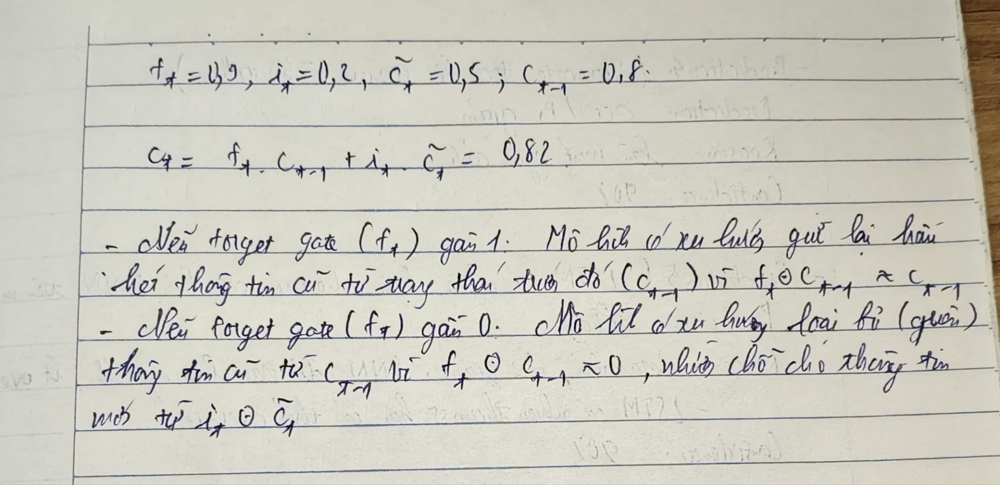

In [8]:
class SequenceClassifier(nn.Module):
    def __init__(self, model_type, vocab_size, embed_dim, hidden_size):
        super().__init__()
        self.model_type = model_type
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)

        if model_type == "RNN":
            self.rnn = nn.RNN(embed_dim, hidden_size, batch_first=True)
        elif model_type == "LSTM":
            self.rnn = nn.LSTM(embed_dim, hidden_size, batch_first=True)
        elif model_type == "GRU":
            self.rnn = nn.GRU(embed_dim, hidden_size, batch_first=True)

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        emb = self.embedding(x)
        if self.model_type == "LSTM":
            out, (h_n, c_n) = self.rnn(emb)
        else:
            out, h_n = self.rnn(emb)
        logits = self.fc(h_n[-1]).squeeze(1)
        return logits

In [9]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def train_and_evaluate(model_type, max_len=100, epochs=5, batch_size=64, lr=1e-3):
    torch.manual_seed(SEED)
    X_tr, pct_ret = encode_texts(train_texts, vocab, max_len)
    X_va, _ = encode_texts(val_texts, vocab, max_len)
    X_te, _ = encode_texts(test_texts, vocab, max_len)

    y_tr = torch.tensor(train_labels, dtype=torch.float32)
    y_va = torch.tensor(val_labels, dtype=torch.float32)
    y_te = torch.tensor(test_labels, dtype=torch.float32)

    train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(TensorDataset(X_va, y_va), batch_size=batch_size)
    test_loader = DataLoader(TensorDataset(X_te, y_te), batch_size=batch_size)

    model = SequenceClassifier(model_type, len(vocab), embed_dim=100, hidden_size=128).to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    train_losses, val_losses = [], []
    t0 = time.time()

    for epoch in range(epochs):
        model.train()
        total_tr_loss = 0
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            out = model(bx)
            loss = criterion(out, by)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            total_tr_loss += loss.item() * len(by)
        train_losses.append(total_tr_loss / len(X_tr))

        model.eval()
        total_va_loss = 0
        with torch.no_grad():
            for bx, by in val_loader:
                bx, by = bx.to(device), by.to(device)
                out = model(bx)
                loss = criterion(out, by)
                total_va_loss += loss.item() * len(by)
        val_losses.append(total_va_loss / len(X_va))

    train_time = time.time() - t0

    # Đánh giá trên tập Test
    model.eval()
    preds, probs = [], []
    with torch.no_grad():
        for bx, _ in test_loader:
            bx = bx.to(device)
            p = torch.sigmoid(model(bx)).cpu().numpy()
            probs.extend(p)
            preds.extend((p >= 0.5).astype(int))

    metrics = {
        "Model": model_type,
        "Representation": "Embedding",
        "Max length": max_len,
        "% tokens retained": round(pct_ret, 2),
        "Parameters": count_parameters(model),
        "Training time (s)": round(train_time, 2),
        "Val Loss": round(val_losses[-1], 4),
        "Accuracy": round(accuracy_score(test_labels, preds), 4),
        "Precision": round(precision_score(test_labels, preds, zero_division=0), 4),
        "Recall": round(recall_score(test_labels, preds, zero_division=0), 4),
        "F1": round(f1_score(test_labels, preds, zero_division=0), 4)
    }
    return model, metrics, train_losses, val_losses, preds, probs

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

models_dict = {}
histories = {}
preds_dict = {}
exp4_results = [lr_metrics]

for m_type in ["RNN", "LSTM", "GRU"]:
    print(f"Đang huấn luyện {m_type} (max_length=100)...")
    model, metrics, tr_l, va_l, preds, probs = train_and_evaluate(m_type, max_len=100, epochs=5)
    models_dict[m_type] = model
    histories[m_type] = (tr_l, va_l)
    preds_dict[m_type] = (preds, probs)
    exp4_results.append(metrics)

df_exp4 = pd.DataFrame(exp4_results)[["Model", "Representation", "Parameters", "Training time (s)", "Accuracy", "Precision", "Recall", "F1"]]
print(df_exp4.to_string(index=False))
df_exp4.to_csv("results.csv", index=False)

Đang huấn luyện RNN (max_length=100)...
Đang huấn luyện LSTM (max_length=100)...
Đang huấn luyện GRU (max_length=100)...
                       Model Representation  Parameters  Training time (s)  Accuracy  Precision  Recall     F1
Logistic Regression (TF-IDF)         TF-IDF       10001               2.17    0.8685     0.8686  0.8703 0.8694
                         RNN      Embedding     1029569               2.72    0.5870     0.5812  0.6402 0.6093
                        LSTM      Embedding     1117889               3.05    0.7115     0.7093  0.7227 0.7159
                         GRU      Embedding     1088449               2.34    0.6973     0.7403  0.6133 0.6708


RNN có sử dụng thông tin sequence mà TF-IDF không sử dụng.

Kết quả thực nghiệm giữa RNN, LSTM và GRU có phù hợp với Prediction ban đầu không?

- Phù hợp với dự đoán:

  - Về Accuracy và F1: LSTM và GRU đều đạt điểm Accuracy và F1 cao hơn đáng kể so với RNN
  - Về Số lượng tham số (Parameters) và Thời gian huấn luyện (Training time): GRU chạy nhanh hơn LSTM nhưng vẫn đạt độ chính xác/F1 tương đương hoặc rất sát LSTM

# 6, Sequence length experiment

## Experiment 2 & 5 - Thử nghiệm max_length $\in \{50, 100, 200\}$

LSTM với max_length = 50...
LSTM với max_length = 100...
LSTM với max_length = 200...
 Max length  % tokens retained  Training time (s)  Val Loss  Accuracy     F1
         50              20.96               2.44    0.6135    0.6935 0.6982
        100              40.53               2.98    0.5605    0.7115 0.7159
        200              67.40               4.84    0.5611    0.7652 0.7688


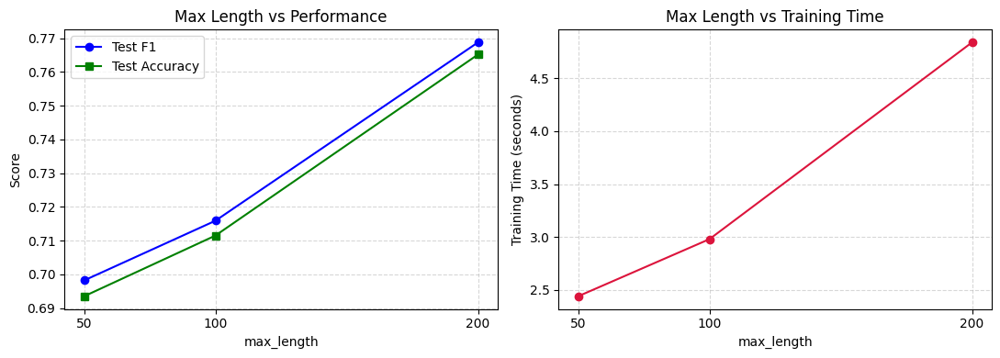

In [11]:
seq_lengths = [50, 100, 200]
seq_exp_results = []

for length in seq_lengths:
    print(f"LSTM với max_length = {length}...")
    _, metrics, _, _, _, _ = train_and_evaluate("LSTM", max_len=length, epochs=5)
    seq_exp_results.append(metrics)

df_seq = pd.DataFrame(seq_exp_results)[["Max length", "% tokens retained", "Training time (s)", "Val Loss", "Accuracy", "F1"]]
print(df_seq.to_string(index=False))

# Vẽ đồ thị
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(df_seq["Max length"], df_seq["F1"], marker='o', label="Test F1", color="blue")
axes[0].plot(df_seq["Max length"], df_seq["Accuracy"], marker='s', label="Test Accuracy", color="green")
axes[0].set_title("Max Length vs Performance")
axes[0].set_xlabel("max_length")
axes[0].set_ylabel("Score")
axes[0].set_xticks(seq_lengths)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].plot(df_seq["Max length"], df_seq["Training time (s)"], marker='o', color="crimson")
axes[1].set_title("Max Length vs Training Time")
axes[1].set_xlabel("max_length")
axes[1].set_ylabel("Training Time (seconds)")
axes[1].set_xticks(seq_lengths)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Experiment 6 (Long-range dependency) & 26. Application

In [13]:
best_model = models_dict["LSTM"]
best_model.eval()

def predict_sentences(sentences, title):
    print(f"\n {title}")
    X_custom, _ = encode_texts(sentences, vocab, max_len=100)
    with torch.no_grad():
        probs = torch.sigmoid(best_model(X_custom.to(device))).cpu().numpy()
    for s, p in zip(sentences, probs):
        label = "Positive" if p >= 0.5 else "Negative"
        print(f"- Câu: \"{s}\"\n  -> Dự đoán: {label} (Xác suất Positive: {p:.4f})")

In [14]:
# 1. Experiment 6
exp6_sentences = [
    # Từ khóa ở cuối câu
    "The movie was, despite many unnecessary scenes and slow pacing in the first hour, ultimately excellent.",
    "The movie was, despite many unnecessary scenes and slow pacing in the first hour, ultimately terrible.",
    # Từ khóa ở giữa câu
    "Despite many unnecessary scenes, the movie was ultimately excellent even though the ending credits were long.",
    # Từ khóa ở đầu câu
    "Excellent acting and brilliant direction, although the theatre seats were uncomfortable and the popcorn was cold."
]
predict_sentences(exp6_sentences, "EXPERIMENT 6: VỊ TRÍ TỪ KHÓA QUAN TRỌNG")


 EXPERIMENT 6: VỊ TRÍ TỪ KHÓA QUAN TRỌNG
- Câu: "The movie was, despite many unnecessary scenes and slow pacing in the first hour, ultimately excellent."
  -> Dự đoán: Positive (Xác suất Positive: 0.9661)
- Câu: "The movie was, despite many unnecessary scenes and slow pacing in the first hour, ultimately terrible."
  -> Dự đoán: Positive (Xác suất Positive: 0.8321)
- Câu: "Despite many unnecessary scenes, the movie was ultimately excellent even though the ending credits were long."
  -> Dự đoán: Positive (Xác suất Positive: 0.9291)
- Câu: "Excellent acting and brilliant direction, although the theatre seats were uncomfortable and the popcorn was cold."
  -> Dự đoán: Positive (Xác suất Positive: 0.9452)


In [15]:
# 2. 26. Application
app_sentences = [
    "I really enjoyed this movie.",
    "I did not like this movie at all, it was a complete waste of time.",
    "I thought the movie would be terrible, but it was surprisingly good.",
    "At first the plot seemed generic and the characters felt wooden, yet as the story unfolded the emotional depth and cinematography completely won me over and made it one of my favorite films of the year."
]
predict_sentences(app_sentences, "APPLICATION: PHÂN LOẠI CÁC DẠNG REVIEW")


 APPLICATION: PHÂN LOẠI CÁC DẠNG REVIEW
- Câu: "I really enjoyed this movie."
  -> Dự đoán: Positive (Xác suất Positive: 0.9192)
- Câu: "I did not like this movie at all, it was a complete waste of time."
  -> Dự đoán: Negative (Xác suất Positive: 0.0555)
- Câu: "I thought the movie would be terrible, but it was surprisingly good."
  -> Dự đoán: Positive (Xác suất Positive: 0.8618)
- Câu: "At first the plot seemed generic and the characters felt wooden, yet as the story unfolded the emotional depth and cinematography completely won me over and made it one of my favorite films of the year."
  -> Dự đoán: Positive (Xác suất Positive: 0.9763)


Tăng max_length có luôn cải thiện performance không? Nếu max_length quá nhỏ, loại thông tin nào bị mất?

- Tăng max_length từ 50 lên 100 và 200 giúp tăng tỷ lệ phần trăm từ được giữ lại (% tokens retained) và cải thiện Accuracy/F1 nhờ có thêm ngữ cảnh. Tuy nhiên, tăng quá lớn không phải lúc nào cũng cải thiện hiệu năng (đặc biệt với Simple RNN dễ bị suy giảm do vanishing gradient hoặc nhiễu từ các đoạn mô tả lan man)

- Nếu max_length quá nhỏ (ví dụ 30–50 tokens), toàn bộ phần nhận xét tổng kết, các mệnh đề chuyển ý ("however", "but overall...") và kết luận cảm xúc ở nửa sau bài đánh giá sẽ bị cắt mất (truncation).

Có tồn tại trade-off giữa context và computational cost không?

- Có. Khi tăng max_length gấp đôi (từ 50 lên 100, và từ 100 lên 200), số bước tính toán tuần tự qua thời gian tăng tuyến tính theo $T$, làm thời gian huấn luyện tăng lên rõ rệt trong khi mức tăng F1 bắt đầu chậm lại (quy luật hiệu suất giảm dần).

# 7, Quantitative evaluation

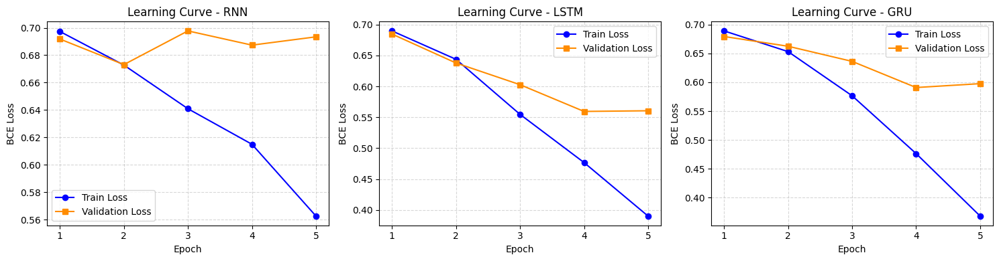

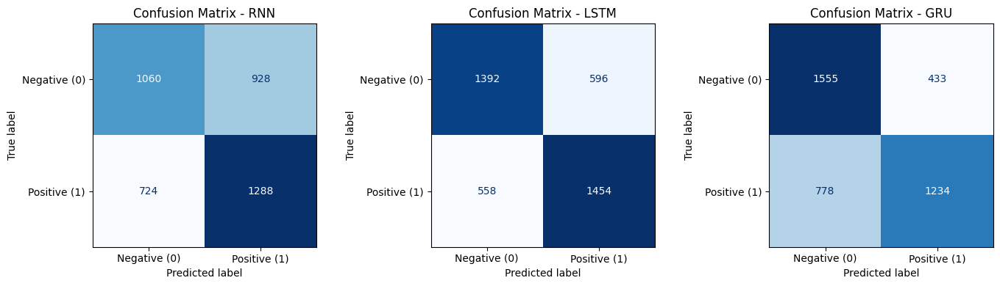

In [16]:
  # 1. Learning Curves (Train Loss vs Validation Loss) cho RNN, LSTM, GRU
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
epochs_range = range(1, 6)

for idx, m_type in enumerate(["RNN", "LSTM", "GRU"]):
    tr_l, va_l = histories[m_type]
    axes[idx].plot(epochs_range, tr_l, marker='o', label='Train Loss', color='blue')
    axes[idx].plot(epochs_range, va_l, marker='s', label='Validation Loss', color='darkorange')
    axes[idx].set_title(f"Learning Curve - {m_type}")
    axes[idx].set_xlabel("Epoch")
    axes[idx].set_ylabel("BCE Loss")
    axes[idx].set_xticks(epochs_range)
    axes[idx].legend()
    axes[idx].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("learning_curves.png", dpi=150)
plt.show()

# 2. Confusion Matrix cho cả 3 mô hình
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for idx, m_type in enumerate(["RNN", "LSTM", "GRU"]):
    preds, _ = preds_dict[m_type]
    cm = confusion_matrix(test_labels, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative (0)", "Positive (1)"])
    disp.plot(ax=axes[idx], cmap="Blues", colorbar=False)
    axes[idx].set_title(f"Confusion Matrix - {m_type}")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

Model có dấu hiệu overfitting không?

- Trong 2–3 epoch đầu tiên, cả Train Loss và Validation Loss đều giảm đều, cho thấy mô hình đang học các đặc trưng tổng quát từ dữ liệu.
- Từ khoảng epoch 3–5 trở đi, Train Loss tiếp tục giảm sâu (do tầng Embedding và Recurrent ghi nhớ tập huấn luyện), trong khi Validation Loss bắt đầu chững lại hoặc tăng nhẹ trở lại. Đây chính là dấu hiệu điển hình của hiện tượng Overfitting (học vẹt trên tập train)

# 8, Error analysis

In [17]:
lstm_preds, lstm_probs = preds_dict["LSTM"]
correct_samples = []
incorrect_samples = []

for text, true_y, pred_y, prob in zip(test_texts, test_labels, lstm_preds, lstm_probs):
    if true_y == pred_y and len(correct_samples) < 3:
        correct_samples.append((text[:250] + "...", true_y, pred_y, round(float(prob), 4)))
    elif true_y != pred_y and len(incorrect_samples) < 3:
        incorrect_samples.append((text[:250] + "...", true_y, pred_y, round(float(prob), 4)))
    if len(correct_samples) == 3 and len(incorrect_samples) == 3:
        break

print("3 MẪU PHÂN LOẠI ĐÚNG")
for i, (txt, t, p, pr) in enumerate(correct_samples, 1):
    print(f"[{i}] True: {t} | Pred: {p} (Prob={pr})\n    Text: {txt}\n")

print("3 MẪU PHÂN LOẠI SAI")
for i, (txt, t, p, pr) in enumerate(incorrect_samples, 1):
    print(f"[{i}] True: {t} | Pred: {p} (Prob={pr})\n    Text: {txt}\n")

3 MẪU PHÂN LOẠI ĐÚNG
[1] True: 1 | Pred: 1 (Prob=0.9236)
    Text: It's one of my favorite movies as much because of the location and music as the story line. Don't matter how many times I watch it, it doesn't seem to ever get old. I can almost say all the lines along with the characters now. The movie is supper fun...

[2] True: 0 | Pred: 0 (Prob=0.1857)
    Text: With all the potential for a good movie in its gorgeous settings, cast, and cinematography, this film's lacklustre script, leaden pace, and wooden performances produced only a major disappointment. With decent direction, editing, and musical score, t...

[3] True: 1 | Pred: 1 (Prob=0.8226)
    Text: As well as being a portrayal of a lesbian love story, FIRE is also a comic satire of middle-class (?) Indian culture. I find this is a quality which is little appreciated about the movie. These two genres (i.e. deep meaningful alternative-love story ...

3 MẪU PHÂN LOẠI SAI
[1] True: 0 | Pred: 1 (Prob=0.628)
    Text: The Movie i

# 9, Reflection

RNN / LSTM / GRU giải quyết được vấn đề gì mà Average Word2Vec không giải quyết tốt?

- RNN / LSTM / GRU giải quyết triệt để điểm mù này bằng cách đọc chuỗi tuần tự từng bước và duy trì trạng thái ẩn phụ thuộc ngữ cảnh

RNN / LSTM / GRU vẫn còn vấn đề gì?

- Nút cổ chai thông tin (Information Bottleneck) trên chuỗi dài
- Không thể song song hóa theo chiều thời gian: Để tính $h_t$, mô hình bắt buộc phải đợi tính xong $h_{t-1}$. Điều này khiến tốc độ huấn luyện chậm và tốn chi phí tính toán khi chuỗi dài.